# CsI–SiPM：残余波动差异的时间分段诊断

2026-11-02。在英文提交 `6f49b781b2f636ee8b6bde81792677b6b2a2819a`（`Evaluate low-frequency noise tradeoffs in CsI SiPM readout`）push并核对远端后继续。[上一轮低频衰减](codex_0001_csi_low_frequency_noise.ipynb)虽然能收窄Am241的F202，却同时破坏PID宽度，两个校准折均保留原参数。本轮从已有实测BIN和原生读出ROOT重新提取，定位差异在脉冲中的时间分布。

**主要发现：** Am241的F202方差差额中，最大的带符号分段贡献落在t10后500–1000 ns；随机分母也有正的统计贡献。用固定分母作诊断时，MC/实测SD比从1.162/1.176变为1.078/1.102，仍有残差。Co60整体F202宽度接近，但2000–2500 ns局部F202均值比只有约0.84–0.85。下一轮需要同时约束早期波动和尾部时间结构。

这是一项统计定位，**尚未修正模拟参数或证明具体物理噪声来源**。当前ADC、正式PID和默认配置不变；没有新实验、新独立Geant4母事件或新增原生读出。模拟波形仍来自已有C++/Geant4链路，不由Python生成或修改。Am241包含α与γ/电子，实测事件没有逐事件粒子真值。


|源|数据/读出|原选择内事件记录数|局部均值非正的记录数|
|---|---|---|---|
|Co60|data|821|0|
|Co60|split_r0|2170|0|
|Co60|split_r1|2173|0|
|Am241|data|316|0|
|Am241|split_r0|1399|0|
|Am241|split_r1|1411|0|

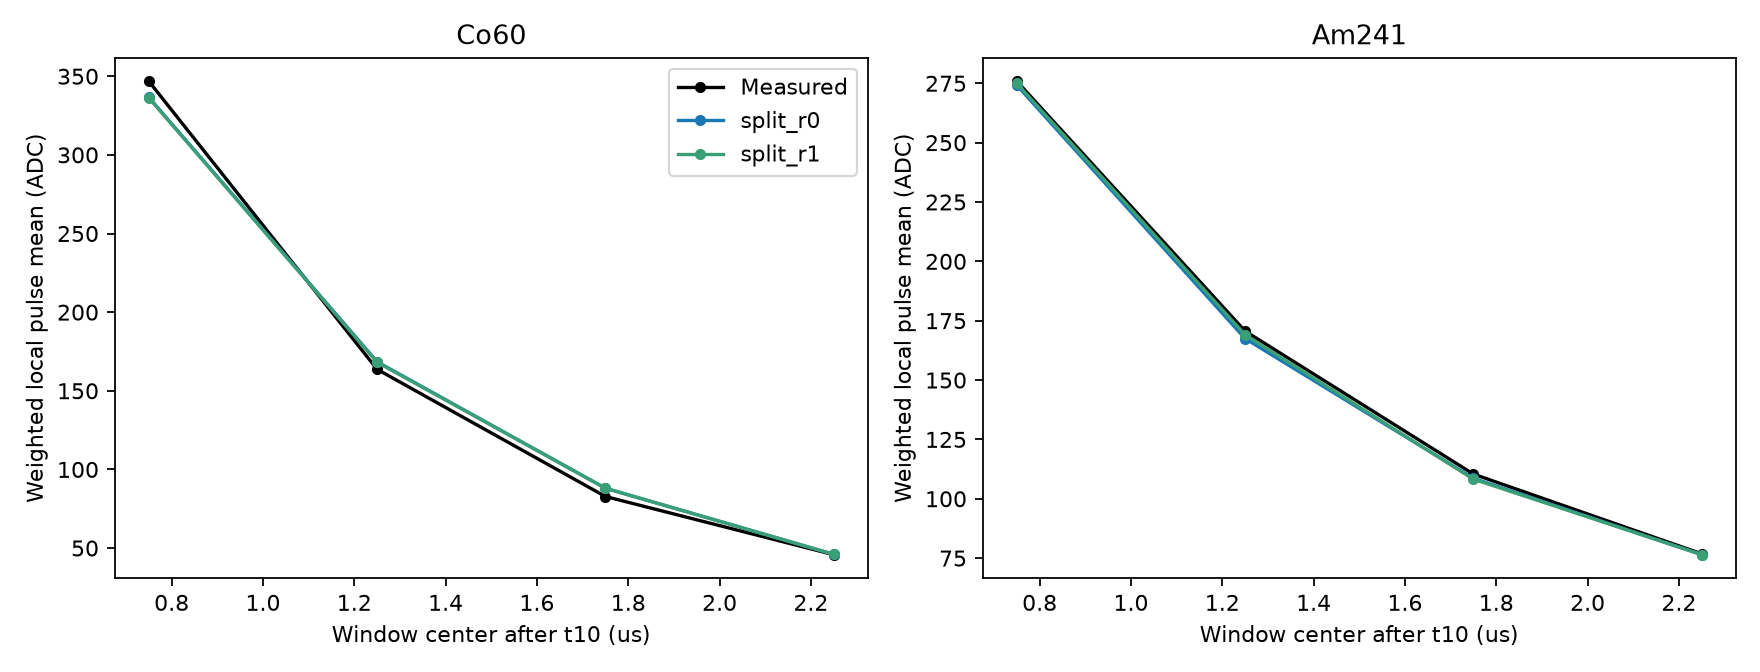

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT = PROJECT/'simulation/results/time_windows_20261102'
def read(path): return json.loads(Path(path).read_text())
def fmt(x): return '不可估计' if x is None else f'{x:.4g}'
def ci(x): return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(y) for y in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head, rows): return '\n'.join(['|'+'|'.join(head)+'|', '|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str, r))+'|' for r in rows])
p = read(OUT/'protocol.json'); a = read(OUT/'analysis.json'); d = read(OUT/'decision.json')
term_names = [name.removeprefix('excess_') for name in p['metrics'][11:18]]
rows = []
for source in a:
    r = read(OUT/'evaluation'/f'{source}_extraction.json')
    for variant, record in r.items():
        rows.append([source, variant, record['active'], record['nonpositive_local_mu']])
display(Markdown(table(['源', '数据/读出', '原选择内事件记录数', '局部均值非正的记录数'], rows)))
display(Image(filename=str(OUT/'figures/time_window_pulse_means.png')))

## 1. 固定窗口、事件与电荷权重

Co60使用run 3，Am241使用run 12；沿用53.2 V数据的last20段、B128基线、原质量条件及完整母事件池下的当前Q选择。Co支持6个Q箱，Am支持3个Q箱；每箱的上下半箱目标质量、折分配和均值参考都保持原样。不因某个局部量不理想而增加切选。表中的MC两条读出共享母事件，不能把事件记录数相加后称作独立样本量。

采样间隔2 ns。原前触发区间从$lceil t_{10}-300
ceil$开始，共200个样点；原信号区间从$lceil t_{10}+250
ceil$开始，共1000个样点。后者固定切成4个相邻250样点窗口，名义范围为t10后500–1000、1000–1500、1500–2000、2000–2500 ns。窗口边界包含向上取整造成的小于2 ns离散偏移。

对原ADC减基线后，沿用25/51/101样点中心滑动均值残差$r=y-mathrm{MA}(y)$，对应F50/F102/F202。各段局部诊断定义为

\[
F_k=\frac{V_k-V_{\rm pre}}{\mu_k},
\]

其中$V_k$和$V_{\rm pre}$是残差样本方差（ddof=1），$\mu_k$是该段原脉冲的平均ADC。局部F不能直接相加得到整体F。所有选中事件的局部$\mu_k$均为正；本轮没有删除或截断事件。下图和表展示F202，全部三尺度的48行局部结果保存于`local_window_table.csv`，其余指标和区间见`analysis.json`。


|源|读出|时间/ns|局部F202均值比|均值比条件95%范围|局部F202 SD比|SD比条件95%范围|
|---|---|---|---|---|---|---|
|Co60|split_r0|500–1000|1.044|[1.012, 1.074] (512/512)|1.039|[0.979, 1.12] (512/512)|
|Co60|split_r0|1000–1500|1.024|[0.9862, 1.059] (512/512)|0.9997|[0.9093, 1.117] (512/512)|
|Co60|split_r0|1500–2000|0.922|[0.8926, 0.966] (512/512)|0.8604|[0.8105, 0.9377] (512/512)|
|Co60|split_r0|2000–2500|0.8418|[0.8113, 0.8785] (512/512)|0.8455|[0.7975, 0.9133] (512/512)|
|Co60|split_r1|500–1000|1.033|[0.9963, 1.065] (512/512)|1.038|[0.9759, 1.113] (512/512)|
|Co60|split_r1|1000–1500|1.012|[0.971, 1.045] (512/512)|0.9825|[0.8951, 1.099] (512/512)|
|Co60|split_r1|1500–2000|0.9296|[0.8979, 0.9732] (512/512)|0.8874|[0.8314, 0.9703] (512/512)|
|Co60|split_r1|2000–2500|0.8463|[0.8128, 0.8833] (512/512)|0.8088|[0.7579, 0.8713] (512/512)|
|Am241|split_r0|500–1000|1.03|[0.9826, 1.081] (512/512)|1.184|[1.103, 1.279] (512/512)|
|Am241|split_r0|1000–1500|0.9893|[0.9425, 1.038] (512/512)|1.124|[1.049, 1.212] (512/512)|
|Am241|split_r0|1500–2000|0.9834|[0.9346, 1.038] (512/512)|0.9478|[0.8637, 1.082] (512/512)|
|Am241|split_r0|2000–2500|1.081|[1.014, 1.131] (512/512)|1.194|[1.038, 1.398] (512/512)|
|Am241|split_r1|500–1000|1.04|[0.993, 1.095] (512/512)|1.208|[1.127, 1.318] (512/512)|
|Am241|split_r1|1000–1500|0.9829|[0.9403, 1.033] (512/512)|1.111|[1.04, 1.202] (512/512)|
|Am241|split_r1|1500–2000|0.9917|[0.9449, 1.048] (512/512)|0.9983|[0.9024, 1.141] (512/512)|
|Am241|split_r1|2000–2500|1.026|[0.9703, 1.072] (512/512)|1.092|[0.9515, 1.283] (512/512)|

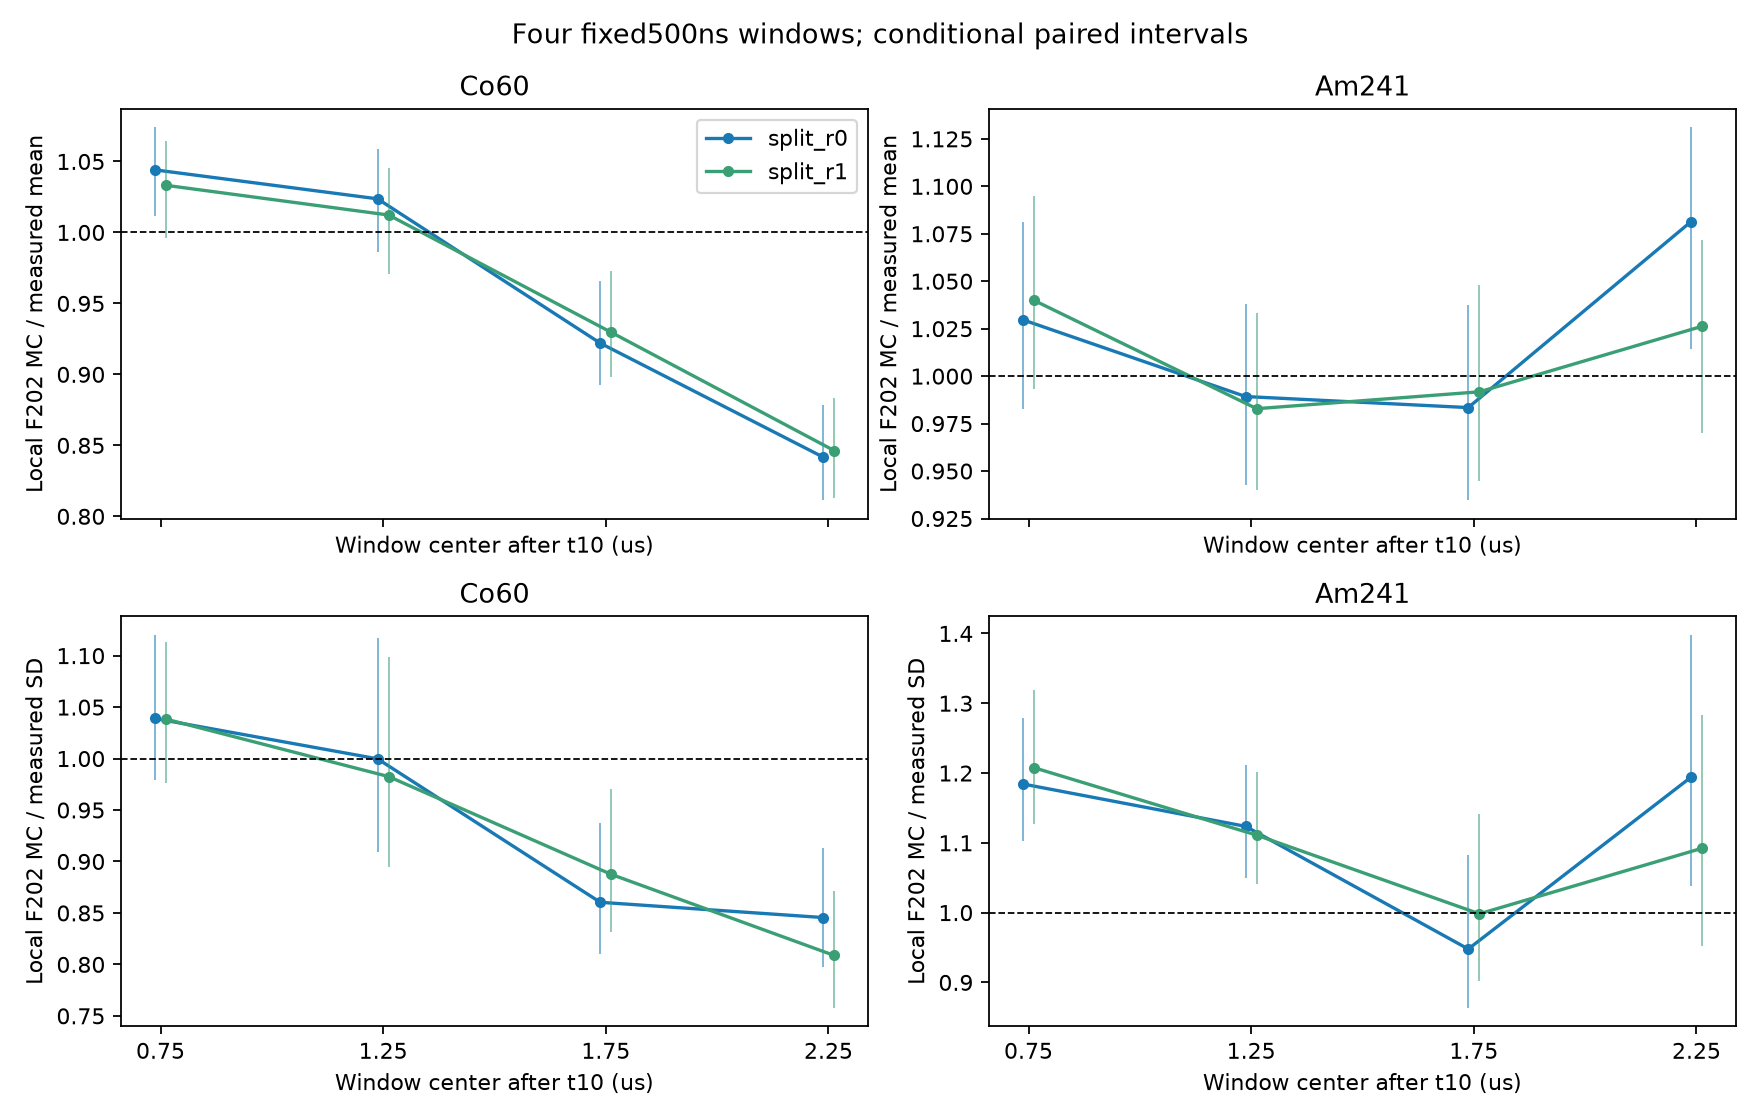

In [2]:
rows = []
for source, group in a.items():
    for variant, scales in group['variants'].items():
        r = scales['202']
        for w in range(4):
            rows.append([source, variant, f'{500+500*w}–{1000+500*w}', fmt(r['point'][f'local_mean_ratio_w{w}']), ci(r['CI95'][f'local_mean_ratio_w{w}']), fmt(r['point'][f'local_SD_ratio_w{w}']), ci(r['CI95'][f'local_SD_ratio_w{w}'])])
display(Markdown(table(['源', '读出', '时间/ns', '局部F202均值比', '均值比条件95%范围', '局部F202 SD比', 'SD比条件95%范围'], rows)))
display(Image(filename=str(OUT/'figures/time_window_local_F202.png')))

## 2. 精确还原整体F的七项分解

记四段残差均值为$\bar r_k$，整体残差均值为$\bar r$。样本方差的恒等式为

\[
V_{\rm post}=\sum_{k=1}^{4}\frac{249}{999}V_k
 +\frac{250}{999}\sum_{k=1}^{4}(\bar r_k-\bar r)^2.
\]

使用既有对折、每Q箱的固定脉冲均值$\mu_0$，依次定义四个窗口项、段间均值项、负前触发项，共六个$T_j$；它们均以上式相应项除以$\mu_0$。第七项为

\[
T_7=(V_{\rm post}-V_{\rm pre})\left(\frac1\mu-\frac1{\mu_0}\right),\qquad
\sum_{j=1}^{7}T_j=\frac{V_{\rm post}-V_{\rm pre}}{\mu}=F.
\]

事件内方差使用ddof=1；事件之间的协方差沿用原加权总体矩定义。在每个当前Q箱内保持既有半箱质量，先计算七项协方差$C$，然后对支持Q箱等权平均。因此$\sum_{ij}C_{ij}$必须准确还原原整体F的条件方差。

每项的带符号贡献取$\mathrm{Cov}(T_j,F)=\sum_i C_{ji}$。图表给出MC与实测之差，再除以实测整体F方差。七项之和等于整体方差相对差额。**这些量包括交叉协方差，可以为负，不能当作七种独立噪声功率或因果份额。** 最大贡献是分解后的描述，不表示事先指定了该窗口为唯一检验对象；全部窗口和尺度均保留。


|源|读出|整体方差差额|500–1000|1000–1500|1500–2000|2000–2500|段间均值|负前触发|分母项|
|---|---|---|---|---|---|---|---|---|---|
|Co60|split_r0|0.09287|0.05908|0.0256|-0.0104|0.002803|0.01113|-0.006534|0.01119|
|Co60|split_r1|0.08427|0.06658|0.02178|-0.01157|-0.001746|0.009007|-0.006904|0.007137|
|Am241|split_r0|0.35|0.2102|0.04714|-0.03367|0.01239|0.002007|0.03059|0.08139|
|Am241|split_r1|0.3837|0.262|0.07636|-0.02014|0.005496|0.002552|-0.00812|0.06559|

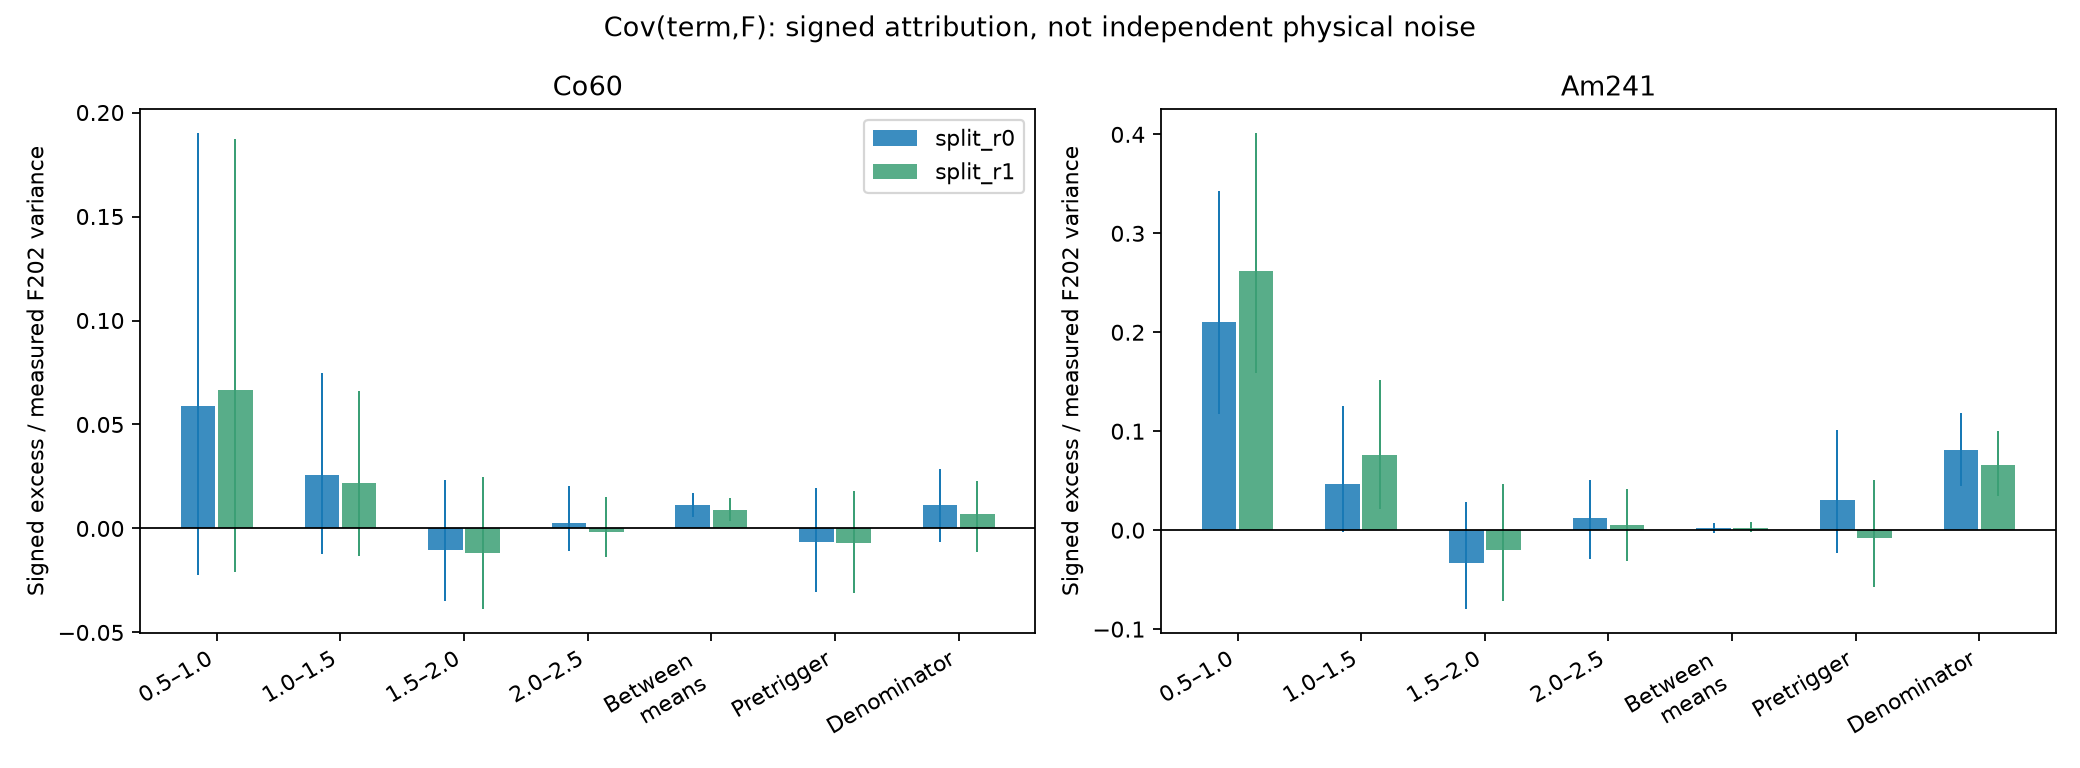

|Am读出|带符号项|差额/实测整体方差|条件95%范围|
|---|---|---|---|
|split_r0|excess_window_500_1000|0.2102|[0.1178, 0.3424] (512/512)|
|split_r0|excess_normalization|0.08139|[0.04435, 0.1188] (512/512)|
|split_r1|excess_window_500_1000|0.262|[0.1585, 0.4018] (512/512)|
|split_r1|excess_normalization|0.06559|[0.03469, 0.1005] (512/512)|

In [3]:
rows = []
for source, group in a.items():
    for variant, scales in group['variants'].items():
        r = scales['202']; point = r['point']
        rows.append([source, variant, fmt(point['global_variance_excess']), *[fmt(point['excess_'+term]) for term in term_names]])
display(Markdown(table(['源', '读出', '整体方差差额', '500–1000', '1000–1500', '1500–2000', '2000–2500', '段间均值', '负前触发', '分母项'], rows)))
display(Image(filename=str(OUT/'figures/time_window_excess_terms.png')))
rows = []
for variant in ['split_r0', 'split_r1']:
    r = a['Am241']['variants'][variant]['202']
    for name in ['excess_window_500_1000', 'excess_normalization']:
        rows.append([variant, name, fmt(r['point'][name]), ci(r['CI95'][name])])
display(Markdown(table(['Am读出', '带符号项', '差额/实测整体方差', '条件95%范围'], rows)))

## 3. 段间协方差与局部宽度需要一起看

另将整体方差拆为三组：四个窗口项的对角方差之和、这些窗口之间全部非对角协方差之和、其余所有项。对称矩阵的非对角元素计入两次，三组严格相加为整体方差。该分组与前面的七项行和分解是同一矩阵的不同汇总，不能再次相加。

Am241的第一个窗口对角项偏大，段间交叉协方差也有正差额。Co60的四个窗口对角方差差额之和略负，但段间交叉项为正，说明整体宽度接近可能同时包含方向不同的局部差异。图中数值是固定分母窗口项的协方差差额，不是原ADC样点间的协方差，也不是局部$F_k$协方差。


|源|读出|分组|差额/实测整体方差|条件95%范围|
|---|---|---|---|---|
|Co60|split_r0|quarter_diagonal_excess|-0.005463|[-0.08036, 0.1076] (512/512)|
|Co60|split_r0|quarter_cross_covariance_excess|0.1131|[0.04674, 0.2254] (512/512)|
|Co60|split_r0|other_covariance_excess|-0.01473|[-0.06536, 0.03709] (512/512)|
|Co60|split_r1|quarter_diagonal_excess|-0.01638|[-0.0996, 0.09603] (512/512)|
|Co60|split_r1|quarter_cross_covariance_excess|0.1156|[0.04971, 0.2307] (512/512)|
|Co60|split_r1|other_covariance_excess|-0.01496|[-0.06378, 0.03964] (512/512)|
|Am241|split_r0|quarter_diagonal_excess|0.1302|[0.02587, 0.2672] (512/512)|
|Am241|split_r0|quarter_cross_covariance_excess|0.06478|[-0.07539, 0.2091] (512/512)|
|Am241|split_r0|other_covariance_excess|0.1551|[0.04851, 0.3047] (512/512)|
|Am241|split_r1|quarter_diagonal_excess|0.1898|[0.06437, 0.3535] (512/512)|
|Am241|split_r1|quarter_cross_covariance_excess|0.08777|[-0.04176, 0.2299] (512/512)|
|Am241|split_r1|other_covariance_excess|0.1062|[0.009804, 0.2354] (512/512)|

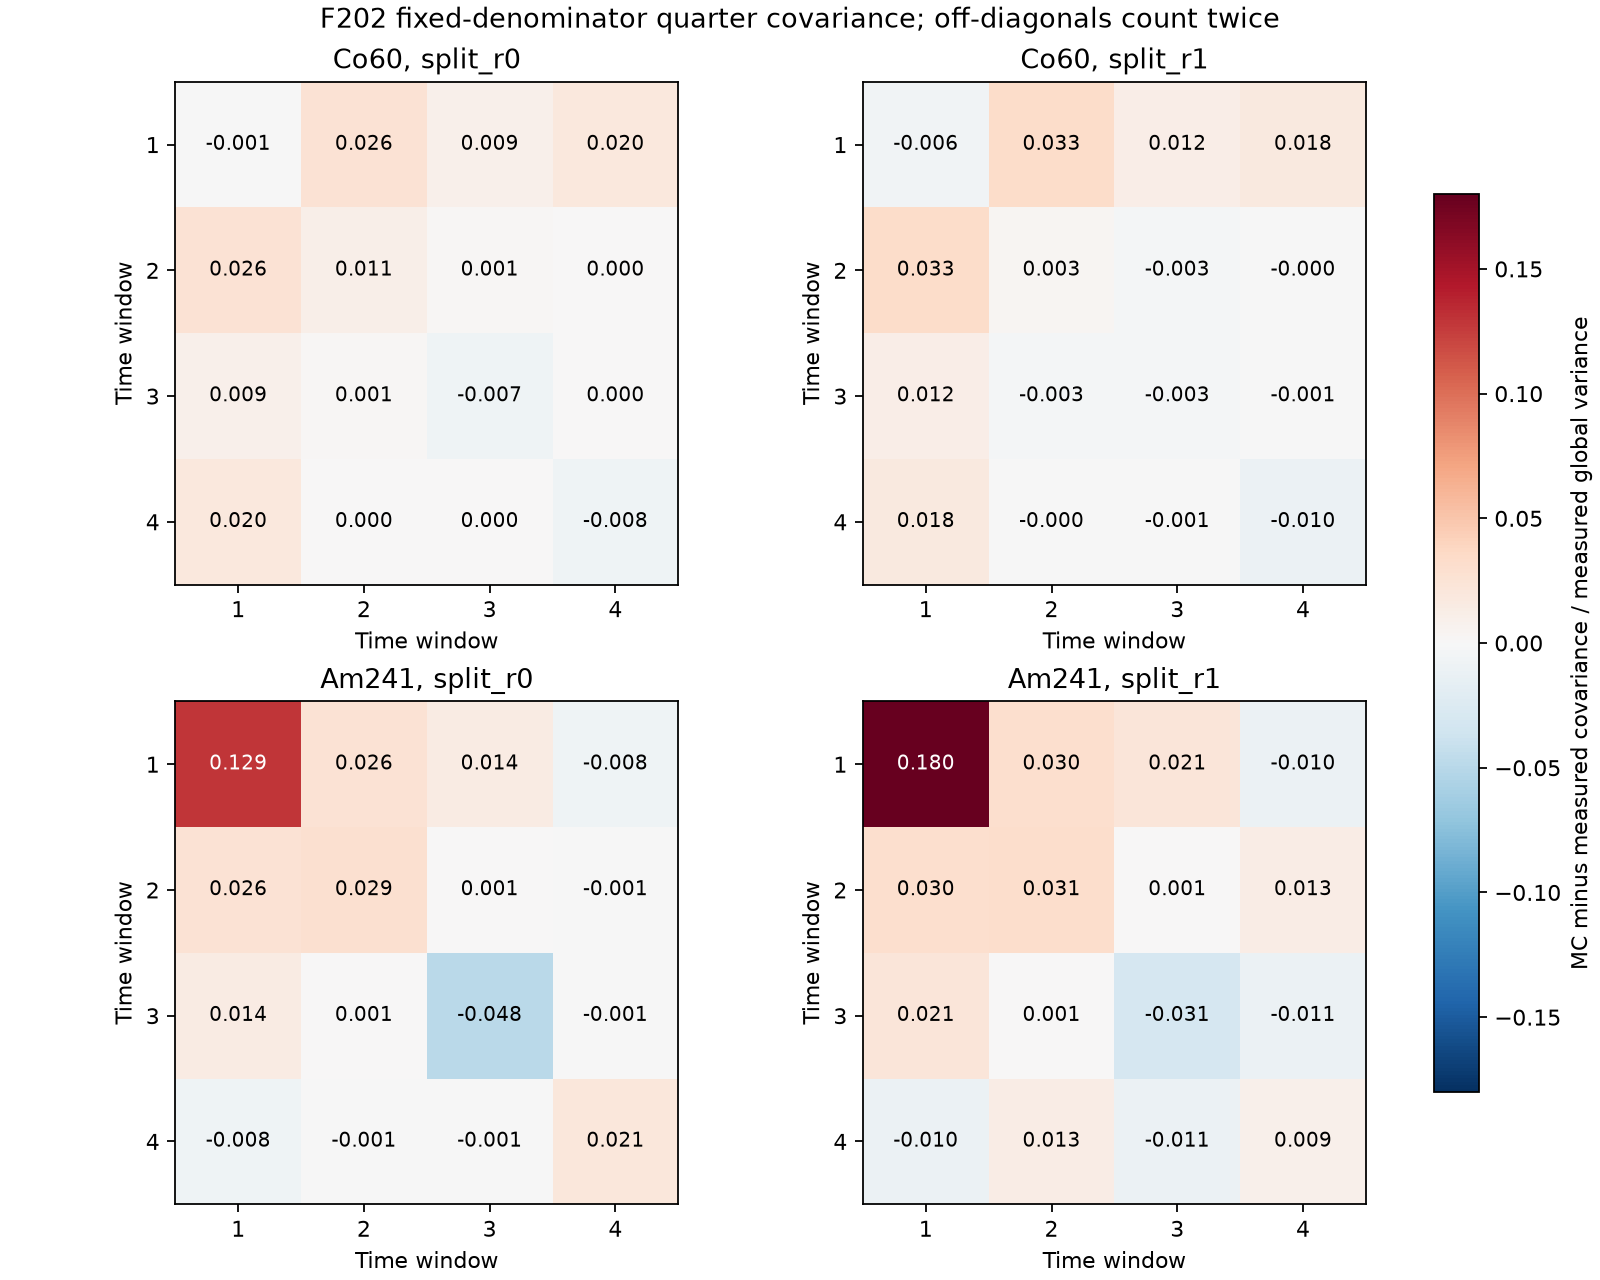

In [4]:
rows = []
for source, group in a.items():
    for variant, scales in group['variants'].items():
        r = scales['202']
        for name in ['quarter_diagonal_excess', 'quarter_cross_covariance_excess', 'other_covariance_excess']:
            rows.append([source, variant, name, fmt(r['point'][name]), ci(r['CI95'][name])])
display(Markdown(table(['源', '读出', '分组', '差额/实测整体方差', '条件95%范围'], rows)))
display(Image(filename=str(OUT/'figures/time_window_cross_covariance.png')))

## 4. 固定分母对照、分折和不确定度

固定分母诊断使用前六项之和，即$(V_{\rm post}-V_{\rm pre})/\mu_0$，同时作用于MC与实测。其宽度比更接近1，只表示随机分母与分子耦合影响了原F的统计宽度，不能据此改写原ADC或宣布PID已改善。七项中的分母行和含一份与其他项的交叉协方差；删除第七项时总方差还会去掉另一份交叉项，所以不能把该行和直接当作固定分母造成的总变化。

直接沿用前轮512组实测事件块和MC母事件的配对计数，不重新抽样窗口，不重拟合，不把相同母事件的两个读出当作独立实验。各尺度整体SD比的点估计及全部512次结果均须与前轮闭合。区间固定拟合、Q参考、选择、已实现噪声，未含模型选择、重拟合或系统误差，也未作多重比较校正。两折数值只作敏感性检查；当前样本已被反复探索，不是新盲验证。


|源|读出|尺度/ns|原F SD比|原F条件95%范围|固定分母SD比|固定分母条件95%范围|
|---|---|---|---|---|---|---|
|Co60|split_r0|50|1.073|[0.9423, 1.211] (512/512)|1.065|[0.9407, 1.193] (512/512)|
|Co60|split_r0|102|0.994|[0.9162, 1.085] (512/512)|0.9842|[0.9015, 1.074] (512/512)|
|Co60|split_r0|202|1.045|[0.9947, 1.122] (512/512)|1.035|[0.9781, 1.118] (512/512)|
|Co60|split_r1|50|0.9401|[0.8448, 1.034] (512/512)|0.9432|[0.85, 1.034] (512/512)|
|Co60|split_r1|102|0.9509|[0.8844, 1.025] (512/512)|0.9529|[0.8797, 1.027] (512/512)|
|Co60|split_r1|202|1.041|[0.9898, 1.121] (512/512)|1.034|[0.9809, 1.117] (512/512)|
|Am241|split_r0|50|0.9611|[0.8991, 1.043] (512/512)|0.9191|[0.852, 1.008] (512/512)|
|Am241|split_r0|102|1.027|[0.9633, 1.109] (512/512)|0.9647|[0.906, 1.041] (512/512)|
|Am241|split_r0|202|1.162|[1.087, 1.268] (512/512)|1.078|[1.005, 1.185] (512/512)|
|Am241|split_r1|50|0.9646|[0.9004, 1.045] (512/512)|0.9172|[0.8515, 1.003] (512/512)|
|Am241|split_r1|102|1.069|[0.9942, 1.16] (512/512)|1.019|[0.9518, 1.108] (512/512)|
|Am241|split_r1|202|1.176|[1.103, 1.285] (512/512)|1.102|[1.027, 1.209] (512/512)|

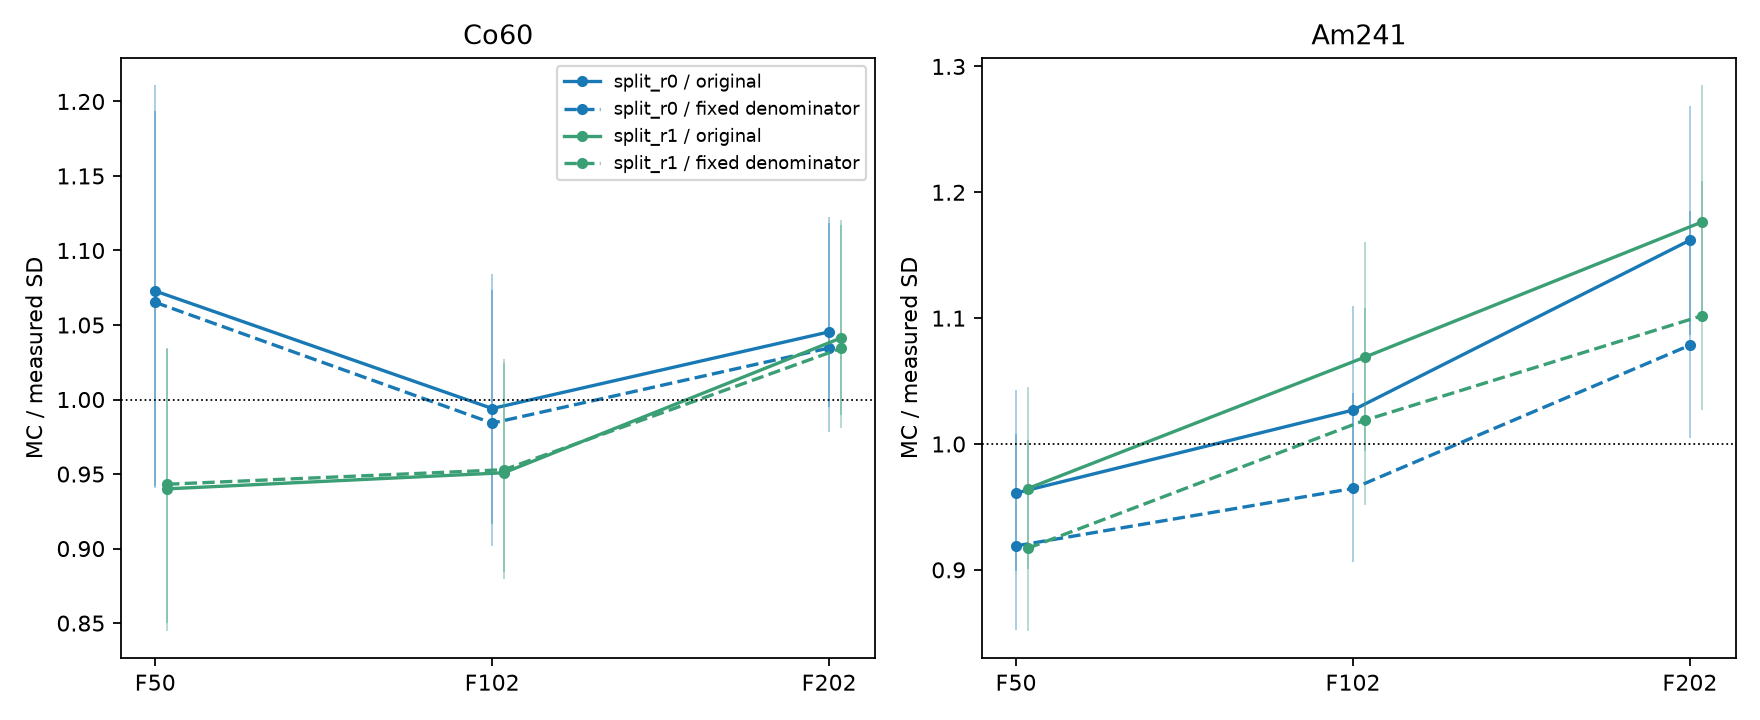

|源|评价折|读出|F202 SD比|固定分母SD比|首窗口贡献|分母贡献|
|---|---|---|---|---|---|---|
|Co60|0|split_r0|1.071|1.041|0.118|0.0322|
|Co60|0|split_r1|1.076|1.058|0.1328|0.01771|
|Co60|1|split_r0|1.059|1.046|0.03902|0.0119|
|Co60|1|split_r1|1.049|1.028|0.04492|0.02119|
|Am241|0|split_r0|1.236|1.127|0.2707|0.1169|
|Am241|0|split_r1|1.2|1.119|0.271|0.08028|
|Am241|1|split_r0|1.106|1.042|0.1497|0.05462|
|Am241|1|split_r1|1.16|1.088|0.2365|0.05618|

**下一步：**以四时段均值、离散度和段间协方差共同约束下一轮模型。先核查差额集中的时段及其信号强度依赖，再测试时间依赖的信号残差包络；保留已匹配的PID协方差与平均波形，不由一个带符号贡献直接指定物理噪声机制。

边界：四段、三个滤波尺度和两个读出共享事件，不是独立重复试验；区间没有多重比较校正。

边界：Cov(term,F)是带符号统计贡献，可为负；包含脉冲曲率、信号/源混合、噪声相关性、归一化和有限参考误差，不能视作独立物理噪声强度。

边界：固定分母及局部F仅用于诊断，没有替换原ADC、原F或正式PID。

边界：512组区间完全继承已有实验块/母事件计数，固定拟合、参考、切选与噪声实现，不含模型选择、重新拟合或系统误差。

边界：既有数据已反复探索，不能称盲验证或证明等效；Am源包括alpha与gamma/电子，实验没有逐事件粒子真值。

In [5]:
rows = []
for source, group in a.items():
    for variant, scales in group['variants'].items():
        for scale, r in scales.items():
            rows.append([source, variant, scale, fmt(r['point']['global_SD_ratio']), ci(r['CI95']['global_SD_ratio']), fmt(r['point']['fixed_denominator_SD_ratio']), ci(r['CI95']['fixed_denominator_SD_ratio'])])
display(Markdown(table(['源', '读出', '尺度/ns', '原F SD比', '原F条件95%范围', '固定分母SD比', '固定分母条件95%范围'], rows)))
display(Image(filename=str(OUT/'figures/time_window_denominator.png')))
rows = []
for source, group in a.items():
    for fold, variants in group['fold_checks'].items():
        for variant, values in variants.items():
            r = dict(zip(p['metrics'], values[2]))
            rows.append([source, fold, variant, fmt(r['global_SD_ratio']), fmt(r['fixed_denominator_SD_ratio']), fmt(r['excess_window_500_1000']), fmt(r['excess_normalization'])])
display(Markdown(table(['源', '评价折', '读出', 'F202 SD比', '固定分母SD比', '首窗口贡献', '分母贡献'], rows)))
display(Markdown('**下一步：**'+d['next_work_zh']))
for limit in d['limitations_zh']:
    display(Markdown('边界：'+limit))

## 5. 复现和核验范围

实际流程为 `prepare_time_windows.py` → `extract_time_windows.py` → `analyze_time_windows.py` → `report_time_windows.py` → 本笔记生成器 → `verify_time_windows.py`及`--archive`。输入为已有实测BIN、split模型完整池原生ROOT、既有Q参考和512组配对计数；源码、输入哈希和窗口在提取前冻结。完整重跑应使用新结果目录。

`test_time_windows.py`使用独立直接卷积验证合成波形的方差恒等式，并用显式重复事件检查加权协方差。`verify_time_windows.py`再从原始BIN/ROOT抽取真实ADC，以直接卷积重算各项，独立验证点估计和第0/127/511组重采样的中心化加权矩；全部事件的七项和及全部512组整体SD比必须复现旧结果。所有选中事件的局部均值有效性、表格行数、执行单元、嵌入图片及来源哈希均有检查。

`verification.json`记录实际检查数；`record.json`封存结果和源码快照。五幅图均作可视检查。未新增原生读出，未修改默认配置、正式PID或共享文献库。前一轮低频检查已经commit和push；本轮时间分段分析为随后新增的本地工作。
